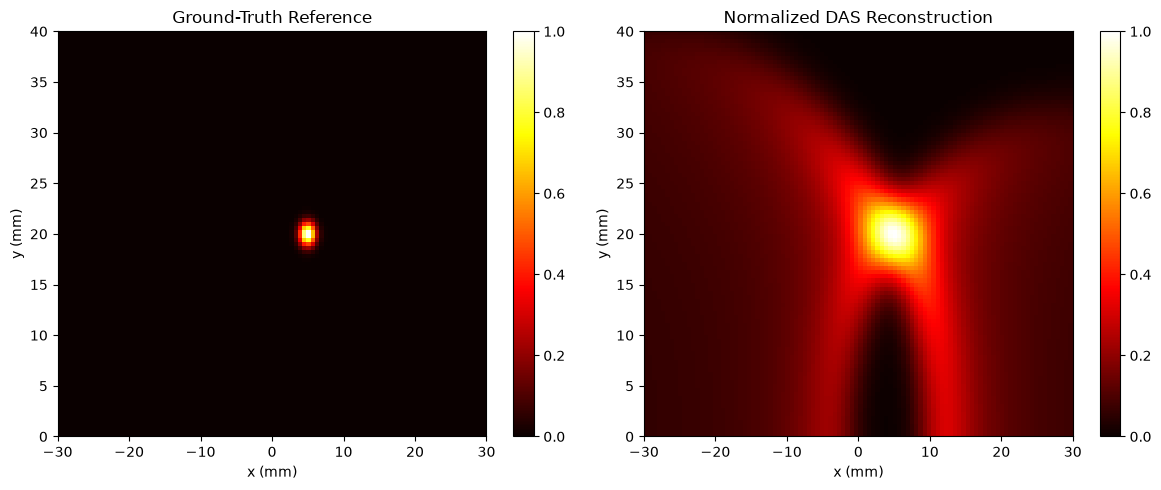

{
    "day": 28,
    "method": "DAS with linear interpolation",
    "reference": "idealized Gaussian point source",
    "image_shape": [
        100,
        100
    ],
    "normalization": "each image scaled to [0, 1]",
    "metrics": {
        "MSE": 0.033332775445759785,
        "MAE": 0.13514103954894868,
        "SNR_dB": -15.652097852610666,
        "PSNR_dB": 14.771285234053305,
        "SSIM_approx": 0.11334350541348563
    },
    "notes": [
        "SNR uses reference mean-square power divided by MSE.",
        "PSNR uses a data range of 1.",
        "SSIM_approx is a Gaussian-filter-based implementation, not the official scikit-image implementation."
    ]
}

Day 28 completed!
Results saved in: ..\outputs


In [1]:

import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import gaussian_filter

# Output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Simulation parameters
c = 1500.0
fs = 10e6
num_sensors = 32

sensor_x = np.linspace(-0.03, 0.03, num_sensors)
sensor_y = np.zeros(num_sensors)

source_x = 0.005
source_y = 0.020

duration = 60e-6
time = np.arange(0, duration, 1 / fs)
dt = time[1] - time[0]

distances = np.sqrt(
    (sensor_x - source_x)**2 +
    (sensor_y - source_y)**2
)
arrival_times = distances / c

signals = np.zeros((num_sensors, len(time)))
pulse_width = 1.5e-6

for i in range(num_sensors):
    signals[i] = np.exp(
        -0.5 * ((time - arrival_times[i]) / pulse_width)**2
    )

# 2. Image grid
image_size = 100
x_grid = np.linspace(-0.03, 0.03, image_size)
y_grid = np.linspace(0.0, 0.04, image_size)
X, Y = np.meshgrid(x_grid, y_grid)

# 3. DAS reconstruction with linear interpolation
reconstruction = np.zeros(X.shape, dtype=float)

for i in range(num_sensors):
    distance = np.sqrt(
        (X - sensor_x[i])**2 +
        (Y - sensor_y[i])**2
    )
    tof = distance / c

    contribution = np.interp(
        tof.ravel(),
        time,
        signals[i],
        left=0.0,
        right=0.0
    ).reshape(X.shape)

    reconstruction += contribution

# 4. Generate the same idealized reference as Day 27
sigma = 0.8e-3

reference = np.exp(
    -(
        (X - source_x)**2 +
        (Y - source_y)**2
    ) / (2 * sigma**2)
)

reference /= np.max(reference)

# 5. Normalize reconstruction to [0, 1]
rec_max = np.max(reconstruction)

if rec_max <= 0:
    raise ValueError("Reconstruction has no positive intensity.")

reconstruction_norm = reconstruction / rec_max

# 6. Calculate image quality metrics
def calculate_metrics(reference, reconstructed):
    reference = np.asarray(reference, dtype=float)
    reconstructed = np.asarray(reconstructed, dtype=float)

    if reference.shape != reconstructed.shape:
        raise ValueError("Images must have the same shape.")

    error = reference - reconstructed
    mse = float(np.mean(error**2))
    mae = float(np.mean(np.abs(error)))

    signal_power = float(np.mean(reference**2))
    noise_power = mse

    if noise_power == 0:
        snr_db = float("inf")
        psnr_db = float("inf")
    else:
        snr_db = float(
            10 * np.log10(
                max(signal_power, np.finfo(float).tiny)
                / noise_power
            )
        )

        psnr_db = float(
            10 * np.log10(1.0 / noise_power)
        )

    # Global SSIM-style comparison
    # Uses local intensity statistics approximated by Gaussian filtering.
    mu_ref = gaussian_filter(reference, sigma=1.5)
    mu_rec = gaussian_filter(reconstructed, sigma=1.5)

    var_ref = (
        gaussian_filter(reference**2, sigma=1.5) - mu_ref**2
    )
    var_rec = (
        gaussian_filter(reconstructed**2, sigma=1.5) - mu_rec**2
    )
    covariance = (
        gaussian_filter(reference * reconstructed, sigma=1.5)
        - mu_ref * mu_rec
    )

    # Stabilizing constants for images with data range 1
    C1 = 0.01**2
    C2 = 0.03**2

    ssim_map = (
        (2 * mu_ref * mu_rec + C1)
        * (2 * covariance + C2)
    ) / (
        (mu_ref**2 + mu_rec**2 + C1)
        * (var_ref + var_rec + C2)
    )

    ssim_value = float(np.mean(ssim_map))

    return {
        "MSE": mse,
        "MAE": mae,
        "SNR_dB": snr_db,
        "PSNR_dB": psnr_db,
        "SSIM_approx": ssim_value
    }

metrics = calculate_metrics(reference, reconstruction_norm)

# 7. Plot reference and reconstruction
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

extent = [
    x_grid[0] * 1000, x_grid[-1] * 1000,
    y_grid[0] * 1000, y_grid[-1] * 1000
]

im0 = axes[0].imshow(
    reference,
    extent=extent,
    origin="lower",
    aspect="auto",
    cmap="hot",
    vmin=0,
    vmax=1
)
axes[0].set_title("Ground-Truth Reference")
axes[0].set_xlabel("x (mm)")
axes[0].set_ylabel("y (mm)")
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(
    reconstruction_norm,
    extent=extent,
    origin="lower",
    aspect="auto",
    cmap="hot",
    vmin=0,
    vmax=1
)
axes[1].set_title("Normalized DAS Reconstruction")
axes[1].set_xlabel("x (mm)")
axes[1].set_ylabel("y (mm)")
fig.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.savefig(
    output_dir / "day28_quality_metrics.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 8. Save results
results = {
    "day": 28,
    "method": "DAS with linear interpolation",
    "reference": "idealized Gaussian point source",
    "image_shape": list(reference.shape),
    "normalization": "each image scaled to [0, 1]",
    "metrics": metrics,
    "notes": [
        "SNR uses reference mean-square power divided by MSE.",
        "PSNR uses a data range of 1.",
        "SSIM_approx is a Gaussian-filter-based implementation, "
        "not the official scikit-image implementation."
    ]
}

with open(
    output_dir / "day28_quality_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4, allow_nan=True)

print(json.dumps(results, indent=4))
print("\nDay 28 completed!")
print(f"Results saved in: {output_dir}")
